# 02 - Ekstraksi Fitur (CNN Embedding) + Pencarian Cosine
Alur: gambar -> CNN pretrained (tanpa layer klasifikasi) -> embedding -> normalisasi L2 -> cosine similarity -> Top-K.

Untuk tuning dipakai **validation** (20% dari TRAIN). TEST tidak disentuh, dipakai sekali di akhir untuk evaluasi resmi.

In [1]:
import json, random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATA_DIR = Path("../data/raw")# sesuaikan: berisi folder TRAIN/ dan TEST/ (satu folder per kelas)
MANIFEST = Path("../data/manifest.csv")
OUT_DIR = Path("../artifacts/embeddings")
OUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_SIZE, BATCH = 224, 32
print("device:", DEVICE)

device: cuda


## 1. Manifest data

In [2]:
EXT = {".jpg", ".jpeg", ".png"}

def build_manifest(data_dir):
    rows = []
    for split_dir in ["TRAIN", "TEST"]:
        for p in sorted((data_dir / split_dir).rglob("*")):
            if p.suffix.lower() in EXT:
                rows.append({"path": p.relative_to(data_dir).as_posix(),
                             "class": p.parent.name,
                             "split": split_dir.lower()})
    return pd.DataFrame(rows)

if MANIFEST.exists():
    df = pd.read_csv(MANIFEST)       # versi bersih dari teman Data (kolom: path, class, split)
else:
    df = build_manifest(DATA_DIR)    # sementara, buatan sendiri

print(df["split"].value_counts())
print("jumlah kelas:", df["class"].nunique())

split
train    1050
test      300
Name: count, dtype: int64
jumlah kelas: 15


In [3]:
train_df = df[df["split"] == "train"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

tr_idx, val_idx = train_test_split(
    train_df.index, test_size=0.2, stratify=train_df["class"], random_state=SEED)
gallery_df = train_df.loc[tr_idx].reset_index(drop=True)   # galeri untuk dicari
val_df = train_df.loc[val_idx].reset_index(drop=True)      # query untuk tuning
print(len(gallery_df), "galeri |", len(val_df), "validation |", len(test_df), "test (jangan dipakai tuning)")

840 galeri | 210 validation | 300 test (jangan dipakai tuning)


## 2. Dataset dan backbone

In [4]:
tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class ImgDS(Dataset):
    def __init__(self, frame): self.paths = frame["path"].tolist()
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return tfm(Image.open(DATA_DIR / self.paths[i]).convert("RGB"))

def get_backbone(name):
    if name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2); m.fc = nn.Identity()
    elif name == "mobilenet_v2":
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V2); m.classifier = nn.Identity()
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1); m.classifier = nn.Identity()
    else:
        raise ValueError(name)
    return m.eval().to(DEVICE)

@torch.no_grad()
def extract(model, frame):
    loader = DataLoader(ImgDS(frame), batch_size=BATCH, num_workers=0)
    feats = np.concatenate([model(x.to(DEVICE)).cpu().numpy() for x in loader])
    return feats / np.linalg.norm(feats, axis=1, keepdims=True)   # normalisasi L2

## 3. Pencarian dan metrik

In [5]:
def search(q, gallery, k=5):
    sims = q @ gallery.T                      # cosine similarity (vektor sudah L2-normal)
    idx = np.argsort(-sims, axis=1)[:, :k]
    return idx, np.take_along_axis(sims, idx, axis=1)

def precision_at_k(sims, q_labels, g_labels, k):
    idx = np.argsort(-sims, axis=1)[:, :k]
    return float((g_labels[idx] == q_labels[:, None]).mean())

def mean_ap(sims, q_labels, g_labels):
    aps = []
    for s, y in zip(sims, q_labels):
        rel = (g_labels[np.argsort(-s)] == y)
        if rel.sum() == 0:
            continue
        prec = np.cumsum(rel) / (np.arange(len(rel)) + 1)
        aps.append((prec * rel).sum() / rel.sum())
    return float(np.mean(aps))

## 4. Baseline: embedding pretrained tanpa fine-tuning

In [7]:
emb, results = {}, []
gl = np.array(gallery_df["class"].tolist())
ql = np.array(val_df["class"].tolist())

for name in ["resnet50", "mobilenet_v2", "efficientnet_b0"]:
    model = get_backbone(name)
    g, q = extract(model, gallery_df), extract(model, val_df)
    emb[name] = (g, q)
    np.save(OUT_DIR / f"{name}_gallery_pretrained.npy", g)
    sims = q @ g.T
    results.append({"model": name, "dim": g.shape[1],
                    "P@5": precision_at_k(sims, ql, gl, 5),
                    "P@10": precision_at_k(sims, ql, gl, 10),
                    "mAP": mean_ap(sims, ql, gl)})

json.dump(gallery_df["path"].tolist(), open(OUT_DIR / "gallery_paths.json", "w"))
pd.DataFrame(results).round(4)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to C:\Users\yuhanidz/.cache\torch\hub\checkpoints\mobilenet_v2-7ebf99e0.pth
100%|██████████| 13.6M/13.6M [00:15<00:00, 943kB/s] 
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\yuhanidz/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth
100%|██████████| 20.5M/20.5M [01:58<00:00, 181kB/s] 


,model,dim,P@5,P@10,mAP
0,resnet50,2048,0.4810,0.4290,0.2491
1,mobilenet_v2,1280,0.5067,0.4395,0.2399
2,efficientnet_b0,1280,0.5410,0.4695,0.2715


## 5. Lihat contoh pencarian (berhasil dan gagal)

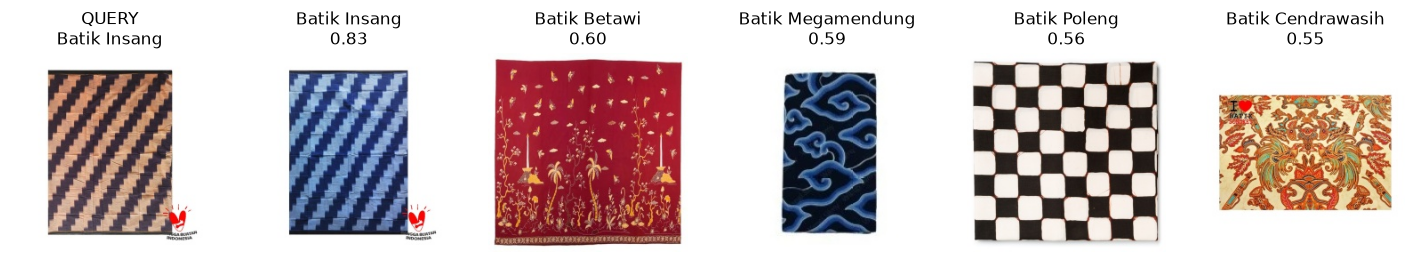

In [8]:
def show_query(i, name="resnet50", k=5):
    g, q = emb[name]
    idx, sc = search(q[i:i+1], g, k)
    fig, ax = plt.subplots(1, k + 1, figsize=(3 * (k + 1), 3))
    ax[0].imshow(Image.open(DATA_DIR / val_df["path"][i]))
    ax[0].set_title("QUERY\n" + val_df["class"][i])
    for j, (gi, s) in enumerate(zip(idx[0], sc[0]), 1):
        ax[j].imshow(Image.open(DATA_DIR / gallery_df["path"][gi]))
        ax[j].set_title(f"{gallery_df['class'][gi]}\n{s:.2f}")
    for a in ax: a.axis("off")
    plt.show()

show_query(0)

## 6. Fungsi untuk backend (nanti dipindah ke modul .py)

In [9]:
_model = get_backbone("resnet50")

@torch.no_grad()
def extract_embedding(image: Image.Image) -> np.ndarray:
    x = tfm(image.convert("RGB")).unsqueeze(0).to(DEVICE)
    f = _model(x).cpu().numpy()[0]
    return f / np.linalg.norm(f)

extract_embedding(Image.open(DATA_DIR / val_df["path"][0])).shape

(2048,)

In [10]:
pd.DataFrame(results).round(4).to_csv("../artifacts/results_baseline.csv", index=False)